# Semilinear fractional Laplacian — numerical report

This code runs Newton and damped Picard for six weight families, prints the baseline/eigenvalue tables, performs the parameter studies, and displays plots.

SEMILINEAR FRACTIONAL LAPLACIAN: NUMERICAL SUMMARY
Equation on (-1,1), exterior value u=1 | s=0.750, N=100, h=1.980198e-02, R=10000
Manufactured exact solution: u*(x)=1+(1-x^2)^s inside (-1,1), and 1 outside.
The solver residual is the final nonlinear algebraic residual norm.

SOLVER PERFORMANCE AND ERRORS
Wgt.  Solver   Conv. Iter.    Residual     Linf error   Rel. L2      lambda_min   
GL    Newton   yes   5        2.107e-13    1.484e-02    3.521e-03    1.62977559   
GL    Picard   yes   76       7.927e-11    1.484e-02    3.521e-03    1.62977559   
PC    Newton   yes   5        9.215e-14    9.833e-03    4.014e-03    1.51492309   
PC    Picard   yes   79       7.792e-11    9.833e-03    4.014e-03    1.51492309   
SP    Newton   yes   5        2.318e-13    1.473e-02    2.111e-03    1.60755801   
SP    Picard   yes   82       9.829e-11    1.473e-02    2.111e-03    1.60755801   
PER   Newton   yes   5        2.054e-13    6.645e-03    1.119e-03    1.60315217   
PER   Picard   yes   81     

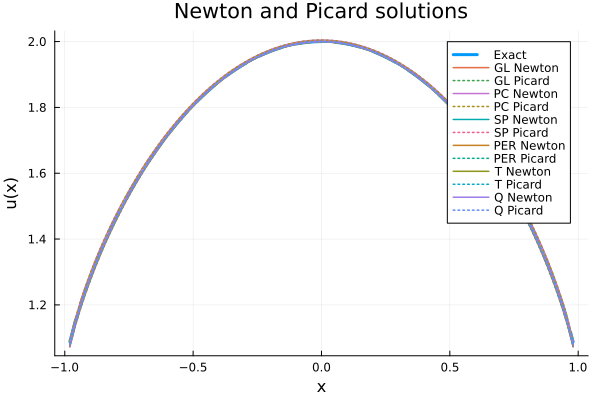

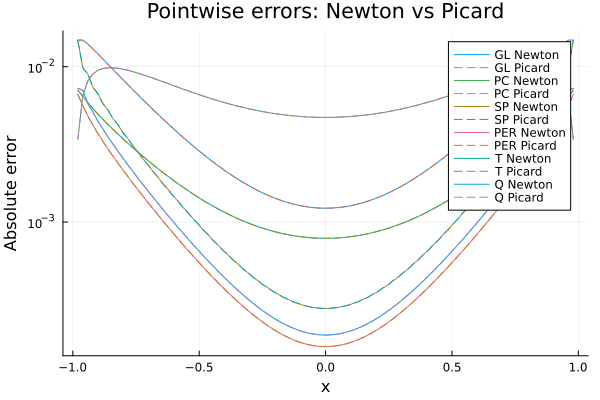


PARAMETER STUDIES

STUDY IN s  (N=60, R=4000)
Wgt.  s       Conv. Newton Linf  Newton RelL2 Picard Linf  Picard RelL2
GL    0.35    yes   8.125e-02    1.017e-02    8.125e-02    1.017e-02   
PC    0.35    yes   2.727e-02    3.068e-03    2.727e-02    3.068e-03   
SP    0.35    yes   3.552e-02    3.748e-03    3.552e-02    3.748e-03   
PER   0.35    yes   2.321e-02    2.629e-03    2.321e-02    2.629e-03   
T     0.35    yes   2.216e-02    2.608e-03    2.216e-02    2.608e-03   
Q     0.35    yes   2.228e-02    2.723e-03    2.228e-02    2.723e-03   
GL    0.60    yes   6.759e-02    1.554e-02    6.759e-02    1.554e-02   
PC    0.60    yes   1.269e-02    1.673e-03    1.269e-02    1.673e-03   
SP    0.60    yes   3.036e-02    4.012e-03    3.036e-02    4.012e-03   
PER   0.60    yes   1.712e-02    2.527e-03    1.712e-02    2.527e-03   
T     0.60    yes   1.750e-02    2.832e-03    1.750e-02    2.832e-03   
Q     0.60    yes   1.786e-02    2.833e-03    1.786e-02    2.833e-03   
GL    0.75    yes

In [7]:
# Semilinear fractional Laplacian on (-1,1)
# Newton's and Picard method with GL, PC, SP, PER, T, and Q weights.
#
# The discrete weights are truncated after R terms.
# For T and Q, s = 1/2 requires separate logarithmic limiting formulas and is therefore rejected by this implementation.

using LinearAlgebra
using SpecialFunctions
using HypergeometricFunctions
using Printf
using Plots

# ----------------------------------------------------------------------
# Study settings (edit these values as needed)
# ----------------------------------------------------------------------

const METHODS = (:GL, :PC, :SP, :PER, :T, :Q)
const TOL = 1.0e-10
const MAXITER = 200
const PICARD_RELAXATION = 0.5

const BASE_S = 0.75
const BASE_N = 100
const BASE_R = 10_000

# Moderate settings keep the full notebook report practical.
const S_VALUES = (0.35, 0.60, 0.75, 0.90)
# Add/remove mesh sizes here to control the mesh-refinement study.
# Example: (40, 60, 80, 100, 120, 160, 200)
const MESH_N_VALUES = (40, 80, 120)
const R_VALUES = (500, 1500, 4000)
const STUDY_N = 60
const STUDY_R = 4000
const STUDY_S = 0.75

const h = 2.0 / (BASE_N + 1)
const X = [-1.0 + j*h for j in 1:BASE_N]

# ----------------------------------------------------------------------
# Fractional Laplacian normalization and exact test problem
# ----------------------------------------------------------------------

# C_{1,s} = 2^(2s) s Gamma(s+1/2)/(sqrt(pi) Gamma(1-s))
function C1(s::Real)
    0 < s < 1 || throw(ArgumentError("s must lie in (0,1)."))

    return 2.0^(2s) * s * gamma(s + 0.5) /
           (sqrt(pi) * gamma(1.0 - s))
end

"""
The function g(x) = (1-x^2)^s inside (-1,1),
extended by zero outside.
"""
function g_exact(x::Real, s::Real)
    return abs(x) < 1.0 ? max(0.0, 1.0 - x^2)^s : 0.0
end

"""
Exact solution:

u*(x) = 1 + (1-x^2)^s, |x| < 1,
         1,             |x| >= 1.
"""
u_exact(x::Real, s::Real) = 1.0 + g_exact(x, s)

"""
For g(x) = (1-x^2)^s_+, (-Delta)^s g is constant on (-1,1):

kappa_s = 4^s Gamma(s+1) Gamma(s+1/2)/sqrt(pi).
"""
function kappa(s::Real)
    0 < s < 1 || throw(ArgumentError("s must lie in (0,1)."))

    return 4.0^s * gamma(s + 1.0) *
           gamma(s + 0.5) / sqrt(pi)
end

"""
Nonlinearity:

F(x,t) = -t^3 + kappa_s + u_exact(x)^3.

The exact solution satisfies:
(-Delta)^s u = F(x,u),  u = 1 outside (-1,1).
"""
function F_nl(x::Real, u::Real, s::Real)
    u_star = u_exact(x, s)

    return -u^3 + kappa(s) + u_star^3
end

"""
Derivative of F with respect to u:

dF/du = -3u^2.
"""
function dF_du(x::Real, u::Real, s::Real)
    return -3.0 * u^2
end

# ----------------------------------------------------------------------
# Weight families
# ----------------------------------------------------------------------

# Piecewise-constant (PC) weights.
function w_PC(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))

    return C1(s) / (2.0*s*h^(2.0*s)) *
           ((m - 0.5)^(-2.0*s) - (m + 0.5)^(-2.0*s))
end

# Spectral (SP) weights; _1F_1 is evaluated by pFq.
function w_SP(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))

    return -h^(-2.0*s) * pi^(2.0*s) / (2.0*s + 1.0) *
           real(pFq((2.0*s + 1.0,), (2.0*s + 2.0,), im*m*pi))
end

# Periodic (PER) weights.
function w_PER(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))

    logw = -2.0*s*log(h) +
           loggamma(m - s) +
           loggamma(1.0 + 2.0*s) +
           log(sin(pi*s)) -
           log(pi) -
           loggamma(m + 1.0 + s)

    return exp(logw)
end

# Grunwald-Letnikov (GL) weights, computed using stable recurrences.
function make_weights_GL(R::Integer, s::Real, h::Real)
    R >= 1 || throw(ArgumentError("R must be positive."))
    0 < s < 1 || throw(ArgumentError("s must lie in (0,1)."))

    W = zeros(Float64, R)
    a = 2.0*s

    if isapprox(a, 1.0; atol=1e-12, rtol=0)
        for m in 1:R
            W[m] = 1.0 / (pi*h*m*(m + 1.0))
        end

        return W

    elseif a < 1.0
        W[1] = h^(-a) * a / (2.0*cos(pi*a/2.0))

        for m in 1:R-1
            W[m+1] = W[m] * (m-a)/(m+1.0)
        end

    else
        W[1] = -h^(-a) / (2.0*cos(pi*a/2.0)) *
               (1.0 + a*(a-1.0)/2.0)

        if R >= 2
            W[2] = h^(-a) * a*(1.0-a)*(2.0-a) /
                   (12.0*cos(pi*a/2.0))

            for m in 2:R-1
                W[m+1] = W[m] * (m+1.0-a)/(m+2.0)
            end
        end
    end

    return W
end

# Auxiliary functions for the T and Q quadrature weights.
function F_aux(t::Real, s::Real)
    abs(2.0*s - 1.0) > 1e-10 ||
        throw(ArgumentError(
            "T/Q weights at s=1/2 need logarithmic limit formulas."
        ))

    return t^(1.0 - 2.0*s) / ((2.0*s - 1.0)*(2.0*s))
end

function Fp_aux(t::Real, s::Real)
    return -t^(-2.0*s)/(2.0*s)
end

function G_aux(t::Real, s::Real)
    abs(2.0*s - 1.0) > 1e-10 ||
        throw(ArgumentError(
            "T/Q weights at s=1/2 need logarithmic limit formulas."
        ))

    return t^(2.0 - 2.0*s) /
           ((2.0 - 2.0*s)*(2.0*s - 1.0)*(2.0*s))
end

Gp_aux(t::Real, s::Real) = F_aux(t, s)
Gpp_aux(t::Real, s::Real) = Fp_aux(t, s)

# Tent / piecewise-linear quadrature (T) weights.
function w_T(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))

    abs(2.0*s - 1.0) > 1e-10 ||
        throw(ArgumentError(
            "T weights at s=1/2 need logarithmic limit formulas."
        ))

    if m == 1
        val = 1.0/(2.0 - 2.0*s) - Fp_aux(1.0, s) +
              F_aux(2.0, s) - F_aux(1.0, s)
    else
        val = F_aux(m + 1.0, s) - 2.0*F_aux(m, s) +
              F_aux(m - 1.0, s)
    end

    return C1(s) * h^(-2.0*s) * val
end

# Piecewise-quadratic quadrature (Q) weights.
function w_Q(m::Integer, s::Real, h::Real)
    m >= 1 || throw(ArgumentError("m must be positive."))

    abs(2.0*s - 1.0) > 1e-10 ||
        throw(ArgumentError(
            "Q weights at s=1/2 need logarithmic limit formulas."
        ))

    if m == 1
        val = 1.0/(2.0 - 2.0*s) - Gpp_aux(1.0, s) -
              (Gp_aux(3.0, s) + 3.0*Gp_aux(1.0, s))/2.0 +
              G_aux(3.0, s) - G_aux(1.0, s)

    elseif iseven(m)
        val = 2.0 * (
            Gp_aux(m + 1.0, s) + Gp_aux(m - 1.0, s) -
            G_aux(m + 1.0, s) + G_aux(m - 1.0, s)
        )

    else
        val = -(Gp_aux(m + 2.0, s) + 6.0*Gp_aux(m, s) +
                Gp_aux(m - 2.0, s))/2.0 +
              G_aux(m + 2.0, s) - G_aux(m - 2.0, s)
    end

    return C1(s) * h^(-2.0*s) * val
end

function make_weights(weight_function, R::Integer, s::Real, h::Real)
    W = Vector{Float64}(undef, R)

    @inbounds for m in 1:R
        W[m] = weight_function(m, s, h)
    end

    all(isfinite, W) ||
        throw(ErrorException(
            "The selected method produced NaN or Inf weights."
        ))

    return W
end

function select_weights(method::Symbol, R::Integer, s::Real, h::Real)
    if method === :GL
        return make_weights_GL(R, s, h)

    elseif method === :PC
        return make_weights(w_PC, R, s, h)

    elseif method === :SP
        return make_weights(w_SP, R, s, h)

    elseif method === :PER
        return make_weights(w_PER, R, s, h)

    elseif method === :T
        return make_weights(w_T, R, s, h)

    elseif method === :Q
        return make_weights(w_Q, R, s, h)

    else
        throw(ArgumentError("Unknown weight method: $method"))
    end
end

# ----------------------------------------------------------------------
# Discrete matrix and nonlinear system
# ----------------------------------------------------------------------

"""
Build the truncated discrete operator for zero exterior data.

The diagonal includes all retained weights; off-diagonal entries
use W[abs(i-j)] whenever the grid indices are distinct.
"""
function build_matrix(W::AbstractVector{<:Real}, N::Integer)
    A = zeros(Float64, N, N)

    diagonal_value = 2.0 * sum(W)
    Rloc = length(W)

    @inbounds for i in 1:N
        A[i, i] = diagonal_value

        for j in 1:N
            if i != j
                m = abs(i-j)

                if m <= Rloc
                    A[i, j] = -W[m]
                end
            end
        end
    end

    return A
end

function nonlinear_residual(V, A, X, s)
    all(isfinite, V) || throw(ArgumentError("The current iterate contains NaN or Inf."))
    Fvec = [F_nl(X[j], 1.0 + V[j], s) for j in eachindex(X)]
    all(isfinite, Fvec) || throw(ErrorException("The nonlinear right-hand side contains NaN or Inf."))

    H = A*V - Fvec
    all(isfinite, H) || throw(ErrorException("The nonlinear residual contains NaN or Inf."))
    return H
end

residual_norm(V, A, X, s) = norm(nonlinear_residual(V, A, X, s), Inf)

# ----------------------------------------------------------------------
# Newton's method with backtracking
# ----------------------------------------------------------------------

function solve_newton(A, X, s; tol=1e-10, maxiter=200)
    V = zeros(Float64, length(X))

    for iter in 1:maxiter
        H = nonlinear_residual(V, A, X, s)
        res = norm(H, Inf)

        if res < tol
            return (V=V, iterations=iter-1, residual=res, converged=true)
        end

        U = 1.0 .+ V
        dF = [dF_du(X[j], U[j], s) for j in eachindex(X)]

        J = A - Diagonal(dF)
        delta = -(J \ H)
        all(isfinite, delta) ||
            return (V=V, iterations=iter, residual=res, converged=false)

        alpha = 1.0
        accepted = false

        while alpha >= 1.0/1024.0
            Vtrial = V + alpha*delta

            if minimum(1.0 .+ Vtrial) > 1e-12
                rtrial = residual_norm(Vtrial, A, X, s)

                if isfinite(rtrial) && rtrial < res
                    V = Vtrial
                    accepted = true
                    break
                end
            end

            alpha /= 2.0
        end

        if !accepted
            return (V=V, iterations=iter, residual=res, converged=false)
        end
    end

    res = residual_norm(V, A, X, s)

    return (V=V, iterations=maxiter, residual=res, converged=false)
end


# ----------------------------------------------------------------------
# Picard (damped fixed-point) method
# ----------------------------------------------------------------------

"""
Damped Picard iteration for A*V = F(x,1+V). The residual is the nonlinear
algebraic residual norm; convergence is not inferred from iterate changes.
"""
function solve_picard(A, X, s; tol=TOL, maxiter=MAXITER,
                      relaxation=PICARD_RELAXATION,
                      min_relaxation=1.0e-8,
                      growth=1.25)
    0.0 < relaxation <= 1.0 ||
        throw(ArgumentError("relaxation must be in (0,1]."))
    0.0 < min_relaxation <= relaxation ||
        throw(ArgumentError("min_relaxation must be in (0, relaxation]."))
    growth >= 1.0 || throw(ArgumentError("growth must be at least 1."))

    # Solve the actual fixed-point equation A*V = F(x,1+V),
    # but safeguard each Picard step with residual-decreasing backtracking.
    V = zeros(Float64, length(X))
    factorA = lu(A)
    omega = relaxation

    for iter in 1:maxiter
        rvec = nonlinear_residual(V, A, X, s)
        res = norm(rvec, Inf)
        res < tol &&
            return (V=V, iterations=iter-1, residual=res, converged=true)

        Fvec = [F_nl(X[j], 1.0 + V[j], s) for j in eachindex(X)]
        Vfixed = factorA \ Fvec
        direction = Vfixed - V

        # Backtracking prevents overshoots (particularly important for the
        # cubic manufactured nonlinearity, whose undamped map is not contractive).
        alpha = min(omega, relaxation)
        accepted = false
        Vtrial = copy(V)
        rtrial = res

        while alpha >= min_relaxation
            candidate = V + alpha*direction
            if all(isfinite, candidate) && minimum(1.0 .+ candidate) > 1.0e-12
                candidate_res = residual_norm(candidate, A, X, s)
                if isfinite(candidate_res) && candidate_res < res
                    Vtrial = candidate
                    rtrial = candidate_res
                    accepted = true
                    break
                end
            end
            alpha *= 0.5
        end

        if !accepted
            return (V=V, iterations=iter, residual=res, converged=false)
        end

        V = Vtrial
        # Grow the next trial step after a successful, safeguarded update.
        omega = min(relaxation, alpha*growth)

        if rtrial < tol
            return (V=V, iterations=iter, residual=rtrial, converged=true)
        end
    end

    res = residual_norm(V, A, X, s)
    return (V=V, iterations=maxiter, residual=res, converged=(res < tol))
end

# ----------------------------------------------------------------------
# Error metrics and configurable experiment driver
# ----------------------------------------------------------------------

function error_metrics(U, Uex, h)
    length(U) == length(Uex) || throw(DimensionMismatch("U and Uex must have the same length."))
    all(isfinite, U) && all(isfinite, Uex) ||
        throw(ArgumentError("Non-finite values detected in a numerical or exact solution."))
    isfinite(h) && h > 0 || throw(ArgumentError("The mesh size h must be finite and positive."))

    E = U .- Uex
    err_inf = norm(E, Inf)
    err_L2 = sqrt(h * sum(abs2, E))
    den_inf = norm(Uex, Inf)
    den_L2 = sqrt(h * sum(abs2, Uex))
    rel_inf = den_inf > 0 ? err_inf / den_inf : err_inf
    rel_L2 = den_L2 > 0 ? err_L2 / den_L2 : err_L2

    all(isfinite, (err_inf, err_L2, rel_inf, rel_L2)) ||
        throw(ErrorException("A non-finite error metric was produced."))
    return (Linf=err_inf, L2=err_L2, relLinf=rel_inf, relL2=rel_L2)
end

# Return `missing` when an observed order is mathematically undefined.
function observed_order(err_old, err_new, h_old, h_new)
    vals = (err_old, err_new, h_old, h_new)
    all(x -> x isa Real && isfinite(x), vals) || return missing
    (err_old > 0 && err_new > 0 && h_old > 0 && h_new > 0 && h_old != h_new) || return missing
    p = log(err_old / err_new) / log(h_old / h_new)
    return isfinite(p) ? p : missing
end

order_string(p) = ismissing(p) ? "--" : @sprintf("%.3f", p)

function run_case(method::Symbol, s::Real, N::Integer, R::Integer)
    0 < s < 1 || throw(ArgumentError("s must lie in (0,1)."))
    N >= 2 || throw(ArgumentError("N must be at least 2."))
    R >= 1 || throw(ArgumentError("R must be positive."))

    hloc = 2.0/(N+1)
    Xloc = [-1.0 + j*hloc for j in 1:N]
    W = select_weights(method, R, s, hloc)
    A = build_matrix(W, N)
    all(isfinite, A) || throw(ErrorException("The discrete matrix contains NaN or Inf for method $method."))

    newton = solve_newton(A, Xloc, s; tol=TOL, maxiter=MAXITER)
    picard = solve_picard(A, Xloc, s; tol=TOL, maxiter=MAXITER)
    Uex = [u_exact(x, s) for x in Xloc]

    return (
        method=method, s=float(s), N=N, h=hloc, R=R,
        lambda_min=eigmin(Symmetric(A)),
        newton=newton, picard=picard,
        error_newton=error_metrics(1.0 .+ newton.V, Uex, hloc),
        error_picard=error_metrics(1.0 .+ picard.V, Uex, hloc),
        X=Xloc, Uex=Uex, Un=1.0 .+ newton.V, Up=1.0 .+ picard.V
    )
end

# ----------------------------------------------------------------------
# Neat console report
# ----------------------------------------------------------------------

function print_solver_table(results)
    println("\nSOLVER PERFORMANCE AND ERRORS")
    @printf("%-5s %-8s %-5s %-8s %-12s %-12s %-12s %-13s\n",
            "Wgt.", "Solver", "Conv.", "Iter.", "Residual",
            "Linf error", "Rel. L2", "lambda_min")
    for r in results, (solver, sol, err) in (
        ("Newton", r.newton, r.error_newton),
        ("Picard", r.picard, r.error_picard)
    )
        @printf("%-5s %-8s %-5s %-8d %-12.3e %-12.3e %-12.3e %-13.8f\n",
                string(r.method), solver, sol.converged ? "yes" : "no",
                sol.iterations, sol.residual, err.Linf, err.relL2, r.lambda_min)
    end
end

function print_eigenvalues(results)
    println("\nMINIMUM EIGENVALUE COMPARISON")
    @printf("%-8s %-20s %-12s\n", "Weight", "lambda_min(A_h)", "Positive?")
    for r in results
        @printf("%-8s %-20.12f %-12s\n",
                string(r.method), r.lambda_min, r.lambda_min > 0 ? "yes" : "no")
    end
end

function study_s(methods=METHODS)
    println("\n", "="^78, "\nSTUDY IN s  (N=$STUDY_N, R=$STUDY_R)\n", "="^78)
    @printf("%-5s %-7s %-5s %-12s %-12s %-12s %-12s\n",
            "Wgt.", "s", "Conv.", "Newton Linf", "Newton RelL2", "Picard Linf", "Picard RelL2")
    rows = NamedTuple[]
    for s0 in S_VALUES, method in methods
        r = run_case(method, s0, STUDY_N, STUDY_R)
        push!(rows, (method=method, s=s0, newton=r.error_newton, picard=r.error_picard,
                     newton_converged=r.newton.converged, picard_converged=r.picard.converged))
        @printf("%-5s %-7.2f %-5s %-12.3e %-12.3e %-12.3e %-12.3e\n",
                string(method), s0, (r.newton.converged && r.picard.converged) ? "yes" : "no",
                r.error_newton.Linf, r.error_newton.relL2,
                r.error_picard.Linf, r.error_picard.relL2)
    end
    return rows
end

function study_mesh(methods=METHODS)
    println("\n", "="^78, "\nMESH REFINEMENT  (s=$STUDY_S, R=$STUDY_R)\n", "="^78)
    println("Observed order uses successive Linf errors; the first row has no order estimate.")
    @printf("%-5s %-6s %-12s %-12s %-9s %-12s %-9s %-13s\n",
            "Wgt.", "N", "h", "Newton Linf", "Order", "Picard Linf", "Order", "lambda_min")
    rows = NamedTuple[]
    for method in methods
        old_h, old_ne, old_pe = nothing, nothing, nothing
        for n0 in MESH_N_VALUES
            r = run_case(method, STUDY_S, n0, STUDY_R)
            on = old_ne === nothing ? missing :
                 observed_order(old_ne, r.error_newton.Linf, old_h, r.h)
            op = old_pe === nothing ? missing :
                 observed_order(old_pe, r.error_picard.Linf, old_h, r.h)
            push!(rows, (method=method, N=n0, h=r.h, newton_error=r.error_newton.Linf,
                         newton_order=on, picard_error=r.error_picard.Linf,
                         picard_order=op, lambda_min=r.lambda_min))
            @printf("%-5s %-6d %-12.4e %-12.4e %-9s %-12.4e %-9s %-13.8f\n",
                    string(method), n0, r.h, r.error_newton.Linf, order_string(on),
                    r.error_picard.Linf, order_string(op), r.lambda_min)
            old_h, old_ne, old_pe = r.h, r.error_newton.Linf, r.error_picard.Linf
        end
    end
    return rows
end

function study_R(methods=METHODS)
    println("\n", "="^78, "\nTRUNCATION STUDY  (s=$STUDY_S, N=$STUDY_N)\n", "="^78)
    @printf("%-5s %-8s %-12s %-12s %-12s %-12s\n",
            "Wgt.", "R", "Newton Linf", "Newton RelL2", "Picard Linf", "Picard RelL2")
    rows = NamedTuple[]
    for method in methods, r0 in R_VALUES
        r = run_case(method, STUDY_S, STUDY_N, r0)
        push!(rows, (method=method, R=r0, newton=r.error_newton, picard=r.error_picard))
        @printf("%-5s %-8d %-12.3e %-12.3e %-12.3e %-12.3e\n",
                string(method), r0, r.error_newton.Linf, r.error_newton.relL2,
                r.error_picard.Linf, r.error_picard.relL2)
    end
    return rows
end

# Number of representative grid points printed in the pointwise-error tables.
# Increase or decrease this value as desired; the points are selected uniformly
# across the baseline grid, including its two endpoints.
const POINTWISE_ERROR_SAMPLES = 9

function print_pointwise_error_table(results)
    println("\nPOINTWISE ABSOLUTE ERRORS (baseline grid)")
    println("Errors are shown at uniformly selected points to keep the tables concise.")
    n = length(results[1].X)
    nsamples = min(POINTWISE_ERROR_SAMPLES, n)
    sample_indices = unique(round.(Int, range(1, n; length=nsamples)))

    for r in results
        println("\nWeight: ", r.method)
        @printf("%12s %18s %18s\n", "x", "Newton error", "Picard error")
        println("-"^52)
        for i in sample_indices
            en = abs(r.Un[i] - r.Uex[i])
            ep = abs(r.Up[i] - r.Uex[i])
            @printf("%12.6f %18.6e %18.6e\n", r.X[i], en, ep)
        end
    end
end

function main_report()
    hbase = 2.0/(BASE_N+1)
    println("="^78)
    println("SEMILINEAR FRACTIONAL LAPLACIAN: NUMERICAL SUMMARY")
    println("="^78)
    @printf("Equation on (-1,1), exterior value u=1 | s=%.3f, N=%d, h=%.6e, R=%d\n",
            BASE_S, BASE_N, hbase, BASE_R)
    println("Manufactured exact solution: u*(x)=1+(1-x^2)^s inside (-1,1), and 1 outside.")
    println("The solver residual is the final nonlinear algebraic residual norm.")

    results = [run_case(method, BASE_S, BASE_N, BASE_R) for method in METHODS]
    print_solver_table(results)
    print_eigenvalues(results)
    print_pointwise_error_table(results)

    p1 = plot(results[1].X, results[1].Uex, label="Exact", linewidth=3,
              linestyle=:dash, xlabel="x", ylabel="u(x)",
              title="Newton and Picard solutions")
    for r in results
        plot!(p1, r.X, r.Un, label="$(r.method) Newton", linewidth=1.5)
        plot!(p1, r.X, r.Up, label="$(r.method) Picard", linewidth=1.5, linestyle=:dot)
    end
    display(p1)

    p2 = plot(results[1].X, max.(abs.(results[1].Un .- results[1].Uex), eps(Float64)),
              yscale=:log10, label="$(results[1].method) Newton",
              xlabel="x", ylabel="Absolute error",
              title="Pointwise errors: Newton vs Picard")
    plot!(p2, results[1].X,
          max.(abs.(results[1].Up .- results[1].Uex), eps(Float64)),
          label="$(results[1].method) Picard", linestyle=:dash)
    for r in results[2:end]
        plot!(p2, r.X, max.(abs.(r.Un .- r.Uex), eps(Float64)),
              label="$(r.method) Newton")
        plot!(p2, r.X, max.(abs.(r.Up .- r.Uex), eps(Float64)),
              label="$(r.method) Picard", linestyle=:dash)
    end
    display(p2)

    println("\nPARAMETER STUDIES")
    s_results = study_s()
    mesh_results = study_mesh()
    truncation_results = study_R()

    return (baseline=results, s_study=s_results,
            mesh_study=mesh_results, truncation_study=truncation_results)
end

main_report()
flush(stdout)
nothing